In [1]:
# pip install pandas numpy statsmodels matplotlib streamlit
#             openpyxl seaborn requests beautifulsoup4

!pip install nba_api

!pip install --upgrade certifi requests urllib3

!pip install pip-system-certs

import requests

r = requests.get(
    "https://stats.nba.com",
    timeout=10
)

print(r.status_code)


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


403



LOADING MY ROSTER

Loading Cade Cunningham
Matched: Cade Cunningham (NBA ID: 1630595)

Loading historical pool for Cade Cunningham
  Loading 2026-27...
    No games found: 2026-27
  Loading 2025-26...
    64 games
  Loading 2024-25...
    70 games
  Loading 2023-24...
    62 games
  Loading 2022-23...
    12 games

Cade Cunningham
Total historical games: 208
Season
2026-27     0
2025-26    64
2024-25    70
2023-24    62
2022-23    12
Name: count, dtype: int64

Loading Grayson Allen
Matched: Grayson Allen (NBA ID: 1628960)

Loading historical pool for Grayson Allen
  Loading 2026-27...
    No games found: 2026-27
  Loading 2025-26...
    51 games
  Loading 2024-25...
    64 games
  Loading 2023-24...
    75 games
  Loading 2022-23...
    72 games

Grayson Allen
Total historical games: 262
Season
2026-27     0
2025-26    51
2024-25    64
2023-24    75
2022-23    72
Name: count, dtype: int64

Loading Jalen Green
Matched: Jalen Green (NBA ID: 1630224)

Loading historical pool for Jalen Gr

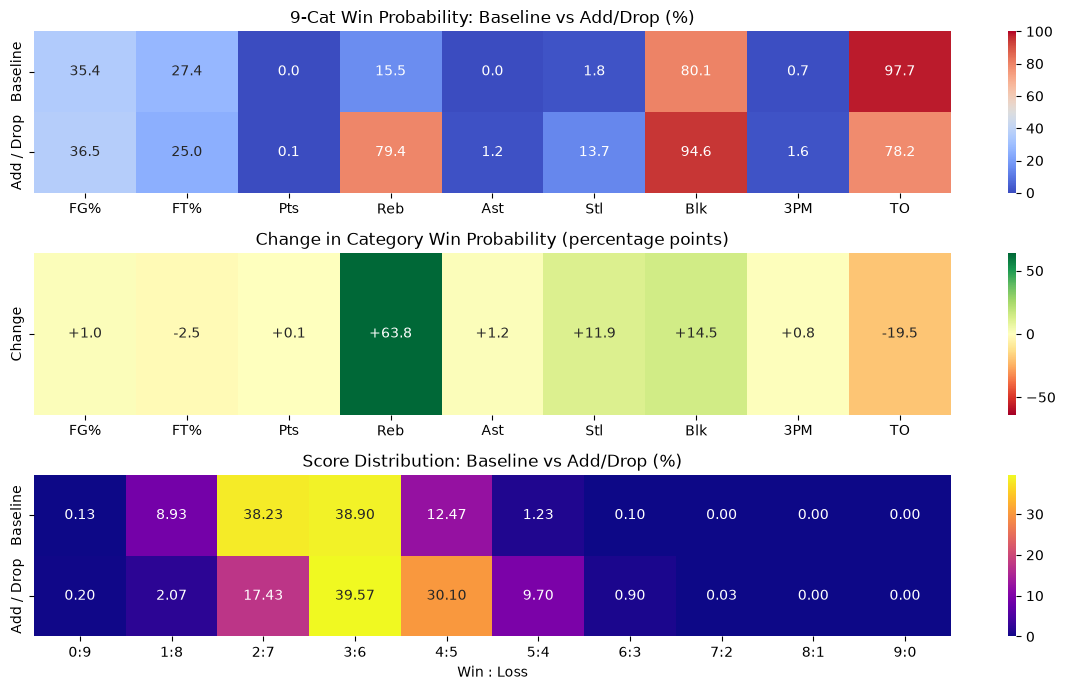

In [32]:
# ============================================================
# FANTASY BASKETBALL H2H 9-CAT
#
# MULTI-SEASON + FAST VECTORIZED VERSION
#
# Historical Data Pool:
# 2026-27
# 2025-26
# 2024-25
# 2023-24
#
# Optimization:
# 1. Weight Cache
# 2. Vectorized Monte Carlo
# ============================================================


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from nba_api.stats.static import players
from nba_api.stats.endpoints import playergamelog


# ============================================================
# 0. MODEL SETTINGS
# ============================================================

DECAY = 0.99

HOME_BOOST = 1.3
AWAY_BOOST = 1.3
OPP_BOOST = 1.8


# ============================================================
# MULTI-SEASON HISTORICAL POOL
# ============================================================

SEASONS = (
    "2026-27",
    "2025-26",
    "2024-25",
    "2023-24",
    "2022-23"
)


STAT_COLS = [
    "Pts",
    "Reb",
    "Ast",
    "Stl",
    "Blk",
    "3PM",
    "TO",
    "FGM",
    "FGA",
    "FTM",
    "FTA"
]


# ============================================================
# 1. FIND PLAYER
# ============================================================

def find_player(name):

    result = players.find_players_by_full_name(name)

    if not result:
        result = players.find_players_by_last_name(name)

    if not result:
        raise ValueError(
            f"找不到球員：{name}"
        )

    if len(result) > 1:

        active = [
            p for p in result
            if p["is_active"]
        ]

        if len(active) == 1:

            result = active

        else:

            print(
                f"\n找到多位符合 '{name}' 的球員："
            )

            for p in result:

                print(
                    p["id"],
                    p["full_name"],
                    "Active:",
                    p["is_active"]
                )

            raise ValueError(
                "請輸入更完整的球員名字"
            )

    player = result[0]

    print(
        f"Matched: "
        f"{player['full_name']} "
        f"(NBA ID: {player['id']})"
    )

    return player


# ============================================================
# 2. GET MULTI-SEASON PLAYER GAME LOG
#
# NEW:
#
# 2026-27
# + 2025-26
# + 2024-25
# + 2023-24
# + 2022-23
#
# 每一季分別抓取
# 然後 concat
# ============================================================

def get_player_df_from_api(
    name,
    seasons=SEASONS
):

    player = find_player(name)

    player_id = player["id"]

    season_dfs = []

    print(
        f"\nLoading historical pool for {name}"
    )

    # --------------------------------------------------------
    # 每一季分別抓
    # --------------------------------------------------------

    for season in seasons:

        print(
            f"  Loading {season}..."
        )

        try:

            df_season = (
                playergamelog.PlayerGameLog(
                    player_id=player_id,
                    season=season,
                    season_type_all_star="Regular Season"
                )
                .get_data_frames()[0]
            )

            # ------------------------------------------------
            # 該季尚未有比賽
            # ------------------------------------------------

            if df_season.empty:

                print(
                    f"    No games found: {season}"
                )

                continue

            # ------------------------------------------------
            # 記住每一列是哪一季
            # ------------------------------------------------

            df_season["Season"] = season

            print(
                f"    {len(df_season)} games"
            )

            season_dfs.append(
                df_season
            )

        except Exception as e:

            print(
                f"    Could not load {season}"
            )

            print(
                f"    Reason: {e}"
            )

    # --------------------------------------------------------
    # 完全沒資料
    # --------------------------------------------------------

    if not season_dfs:

        raise ValueError(
            f"{name} 沒有成功取得任何賽季資料"
        )

    # --------------------------------------------------------
    # 合併所有賽季
    # --------------------------------------------------------

    df = pd.concat(
        season_dfs,
        ignore_index=True
    )

    # --------------------------------------------------------
    # Rename
    # --------------------------------------------------------

    df = df.rename(columns={

        "GAME_DATE": "Date",
        "MATCHUP": "Matchup",
        "WL": "Result",
        "MIN": "Min",

        "FGM": "FGM",
        "FGA": "FGA",
        "FG_PCT": "FG%",

        "FG3M": "3PM",
        "FG3A": "3PA",
        "FG3_PCT": "3P%",

        "FTM": "FTM",
        "FTA": "FTA",
        "FT_PCT": "FT%",

        "OREB": "OR",
        "DREB": "DR",
        "REB": "Reb",

        "AST": "Ast",
        "STL": "Stl",
        "BLK": "Blk",
        "TOV": "TO",

        "PF": "PF",
        "PLUS_MINUS": "+/-",
        "PTS": "Pts"
    })

    df["Date"] = pd.to_datetime(
        df["Date"]
    )

    # ========================================================
    # PARSE MATCHUP
    # ========================================================

    def parse_matchup(m):

        parts = m.split(" ")

        team = parts[0]
        symbol = parts[1]
        opp = parts[2]

        return pd.Series({

            "Team": team,

            "Opp": opp,

            "HomeAway": symbol,

            "IsHome": symbol == "vs"
        })

    extra = (
        df["Matchup"]
        .apply(parse_matchup)
    )

    df = pd.concat(
        [df, extra],
        axis=1
    )

    # --------------------------------------------------------
    # 最重要：
    #
    # 多季資料合併後
    # 按真正比賽日期排序
    #
    # 最新 → 最舊
    # --------------------------------------------------------

    df = (
        df
        .sort_values(
            "Date",
            ascending=False
        )
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Diagnostic
    # --------------------------------------------------------

    print(
        f"\n{name}"
    )

    print(
        f"Total historical games: {len(df)}"
    )

    print(
        df["Season"]
        .value_counts()
        .reindex(seasons)
        .fillna(0)
        .astype(int)
    )

    return df


# ============================================================
# 3. BUILD ROSTER
# ============================================================

def build_roster(
    player_names,
    seasons=SEASONS
):

    roster = {}

    for name in player_names:

        print("\n" + "=" * 60)

        print(
            f"Loading {name}"
        )

        print("=" * 60)

        roster[name] = (
            get_player_df_from_api(
                name,
                seasons=seasons
            )
        )

    return roster


# ============================================================
# 4. LOAD SCHEDULE
# ============================================================

def load_schedule(
    path="schedule.csv"
):

    df = pd.read_csv(path)

    df["date"] = pd.to_datetime(
        df["date"]
    )

    return df


# ============================================================
# 5. GET GAMES IN RANGE
# ============================================================

def get_games_in_range(
    schedule_df,
    team,
    start_date,
    end_date
):

    start_date = pd.to_datetime(
        start_date
    )

    end_date = pd.to_datetime(
        end_date
    )

    mask = (

        (schedule_df["team"] == team)

        &

        (schedule_df["date"] >= start_date)

        &

        (schedule_df["date"] <= end_date)
    )

    return (
        schedule_df[mask]
        .sort_values("date")
        .reset_index(drop=True)
    )


# ============================================================
# 6. SINGLE FUTURE GAME WEIGHT
#
# Recency
# × Home/Away
# × Opponent
# ============================================================

def apply_single_game_weight(
    df,
    game,
    decay=DECAY,
    home_boost=HOME_BOOST,
    away_boost=AWAY_BOOST,
    opp_boost=OPP_BOOST
):

    df = df.copy()

    # --------------------------------------------------------
    # NEW:
    #
    # 不論資料來自哪一季
    # 全部按照真正 Date 排序
    # --------------------------------------------------------

    df = (
        df
        .sort_values(
            "Date",
            ascending=False
        )
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Recency Weight
    #
    # 最新一場 = decay^0
    # 次新一場 = decay^1
    # ...
    # --------------------------------------------------------

    df["Weight"] = (
        decay **
        np.arange(len(df))
    )

    # --------------------------------------------------------
    # Future Game Environment
    # --------------------------------------------------------

    next_is_home = (
        game["home_away"] == "home"
    )

    next_opp = (
        game["opponent"]
    )

    # --------------------------------------------------------
    # Historical Game Environment
    # --------------------------------------------------------

    is_home_sample = (
        df["HomeAway"] == "vs"
    )

    is_away_sample = (
        df["HomeAway"] == "@"
    )

    # --------------------------------------------------------
    # Home / Away Boost
    # --------------------------------------------------------

    if next_is_home:

        df.loc[
            is_home_sample,
            "Weight"
        ] *= home_boost

    else:

        df.loc[
            is_away_sample,
            "Weight"
        ] *= away_boost

    # --------------------------------------------------------
    # Opponent Boost
    # --------------------------------------------------------

    df.loc[
        df["Opp"] == next_opp,
        "Weight"
    ] *= opp_boost

    # --------------------------------------------------------
    # Normalize
    # --------------------------------------------------------

    df["Weight"] = (
        df["Weight"]
        /
        df["Weight"].sum()
    )

    return df


# ============================================================
# 7. PREPARE PLAYER SIMULATION
#
# Weight Cache
# ============================================================

def prepare_player_simulation(
    player_name,
    player_df,
    schedule_df,
    start_date,
    end_date
):

    # --------------------------------------------------------
    # 最新 game log 的 Team
    #
    # 因為 DataFrame 已按照 Date newest -> oldest
    # --------------------------------------------------------

    team = (
        player_df["Team"]
        .iloc[0]
    )

    games_df = (
        get_games_in_range(
            schedule_df,
            team,
            start_date,
            end_date
        )
    )

    prepared_games = []

    for _, game in games_df.iterrows():

        # ----------------------------------------------------
        # Player × Future Game
        #
        # weights 只算一次
        # ----------------------------------------------------

        weighted_df = (
            apply_single_game_weight(
                player_df,
                game
            )
        )

        prepared_games.append({

            "date":
                game["date"],

            "opponent":
                game["opponent"],

            "home_away":
                game["home_away"],

            "weighted_df":
                weighted_df
        })

    return {

        "player":
            player_name,

        "team":
            team,

        "games":
            prepared_games
    }


# ============================================================
# 8. PREPARE ROSTER
# ============================================================

def prepare_roster_simulation(
    roster,
    schedule_df,
    start_date,
    end_date
):

    prepared_roster = {}

    for (
        player_name,
        player_df
    ) in roster.items():

        prepared_roster[
            player_name
        ] = (
            prepare_player_simulation(
                player_name,
                player_df,
                schedule_df,
                start_date,
                end_date
            )
        )

    return prepared_roster


# ============================================================
# 9. VECTORIZED PLAYER SIMULATION
# ============================================================

def simulate_player_vectorized(
    prepared_player,
    n_sim,
    rng
):

    totals = pd.DataFrame(
        0.0,
        index=np.arange(n_sim),
        columns=STAT_COLS
    )

    # --------------------------------------------------------
    # 每場 Future NBA Game
    # --------------------------------------------------------

    for game_info in prepared_player["games"]:

        weighted_df = (
            game_info["weighted_df"]
        )

        weights = (
            weighted_df["Weight"]
            .to_numpy()
        )

        # ----------------------------------------------------
        # 一次產生全部 Monte Carlo draws
        # ----------------------------------------------------

        sampled_indices = rng.choice(
            len(weighted_df),
            size=n_sim,
            replace=True,
            p=weights
        )

        # ----------------------------------------------------
        # Joint Game-Level Bootstrap
        #
        # 整列 Box Score 一起抽
        # ----------------------------------------------------

        sampled_games = (

            weighted_df

            .iloc[sampled_indices]

            [STAT_COLS]

            .reset_index(drop=True)
        )

        totals += sampled_games

    return totals


# ============================================================
# 10. VECTORIZED ROSTER SIMULATION
# ============================================================

def simulate_roster_vectorized(
    prepared_roster,
    n_sim,
    rng
):

    roster_totals = pd.DataFrame(
        0.0,
        index=np.arange(n_sim),
        columns=STAT_COLS
    )

    for (
        player_name,
        prepared_player
    ) in prepared_roster.items():

        player_totals = (
            simulate_player_vectorized(
                prepared_player,
                n_sim,
                rng
            )
        )

        roster_totals += (
            player_totals
        )

    return roster_totals


# ============================================================
# 11. FAST MATCHUP SIMULATION
# ============================================================

def simulate_matchup_fast(
    prepared_my_roster,
    prepared_opp_roster,
    current_my,
    current_opp,
    n_sim=100000,
    random_seed=12345
):

    rng = np.random.default_rng(
        random_seed
    )

    # --------------------------------------------------------
    # Simulate entire future
    # --------------------------------------------------------

    my_future = (
        simulate_roster_vectorized(
            prepared_my_roster,
            n_sim,
            rng
        )
    )

    opp_future = (
        simulate_roster_vectorized(
            prepared_opp_roster,
            n_sim,
            rng
        )
    )

    # ========================================================
    # FG%
    # ========================================================

    my_FGM = (
        current_my["FGM"]
        + my_future["FGM"]
    )

    my_FGA = (
        current_my["FGA"]
        + my_future["FGA"]
    )

    opp_FGM = (
        current_opp["FGM"]
        + opp_future["FGM"]
    )

    opp_FGA = (
        current_opp["FGA"]
        + opp_future["FGA"]
    )

    my_FG_pct = (
        my_FGM / my_FGA
    )

    opp_FG_pct = (
        opp_FGM / opp_FGA
    )

    # ========================================================
    # FT%
    # ========================================================

    my_FTM = (
        current_my["FTM"]
        + my_future["FTM"]
    )

    my_FTA = (
        current_my["FTA"]
        + my_future["FTA"]
    )

    opp_FTM = (
        current_opp["FTM"]
        + opp_future["FTM"]
    )

    opp_FTA = (
        current_opp["FTA"]
        + opp_future["FTA"]
    )

    my_FT_pct = (
        my_FTM / my_FTA
    )

    opp_FT_pct = (
        opp_FTM / opp_FTA
    )

    # ========================================================
    # WIN + MARGIN MATRIX
    # ========================================================

    win_df = pd.DataFrame(
        index=np.arange(n_sim)
    )

    margin_df = pd.DataFrame(
        index=np.arange(n_sim)
    )

    # --------------------------------------------------------
    # FG%
    # --------------------------------------------------------

    win_df["FG%"] = (
        my_FG_pct
        >
        opp_FG_pct
    ).astype(int)

    margin_df["FG%"] = (
        my_FG_pct
        -
        opp_FG_pct
    )

    # --------------------------------------------------------
    # FT%
    # --------------------------------------------------------

    win_df["FT%"] = (
        my_FT_pct
        >
        opp_FT_pct
    ).astype(int)

    margin_df["FT%"] = (
        my_FT_pct
        -
        opp_FT_pct
    )

    # --------------------------------------------------------
    # Counting Categories
    # --------------------------------------------------------

    for cat in [
        "Pts",
        "Reb",
        "Ast",
        "Stl",
        "Blk",
        "3PM"
    ]:

        my_total = (
            current_my[cat]
            +
            my_future[cat]
        )

        opp_total = (
            current_opp[cat]
            +
            opp_future[cat]
        )

        win_df[cat] = (
            my_total
            >
            opp_total
        ).astype(int)

        margin_df[cat] = (
            my_total
            -
            opp_total
        )

    # --------------------------------------------------------
    # TO
    #
    # Lower is better
    # --------------------------------------------------------

    my_TO = (
        current_my["TO"]
        +
        my_future["TO"]
    )

    opp_TO = (
        current_opp["TO"]
        +
        opp_future["TO"]
    )

    win_df["TO"] = (
        my_TO
        <
        opp_TO
    ).astype(int)

    margin_df["TO"] = (
        my_TO
        -
        opp_TO
    )

    # ========================================================
    # CATEGORY RESULTS
    # ========================================================

    categories = [
        "FG%",
        "FT%",
        "Pts",
        "Reb",
        "Ast",
        "Stl",
        "Blk",
        "3PM",
        "TO"
    ]

    category_results = {}

    for cat in categories:

        margins = (
            margin_df[cat]
            .to_numpy()
        )

        category_results[cat] = {

            "win_prob":
                win_df[cat].mean(),

            "avg_margin":
                margins.mean(),

            "p5":
                np.quantile(
                    margins,
                    0.05
                ),

            "p50":
                np.quantile(
                    margins,
                    0.50
                ),

            "p95":
                np.quantile(
                    margins,
                    0.95
                )
        }

    # ========================================================
    # FINAL SCORE DISTRIBUTION
    # ========================================================

    total_wins = (
        win_df.sum(axis=1)
        .to_numpy()
    )

    score_distribution = {

        k:
        np.mean(
            total_wins == k
        )

        for k in range(10)
    }

    p_ge_5 = np.mean(
        total_wins >= 5
    )

    p_ge_6 = np.mean(
        total_wins >= 6
    )

    p_ge_7 = np.mean(
        total_wins >= 7
    )

    return {

        "categories":
            category_results,

        "score_distribution":
            score_distribution,

        "p_ge_5":
            p_ge_5,

        "p_ge_6":
            p_ge_6,

        "p_ge_7":
            p_ge_7,

        "total_wins":
            total_wins,

        "win_df":
            win_df,

        "margin_df":
            margin_df,

        "my_future":
            my_future,

        "opp_future":
            opp_future
    }


# ============================================================
# 12. CREATE ADD / DROP ROSTER
#
# UPDATED:
# Add Player 也抓 Multi-Season Pool
# ============================================================

def create_add_drop_roster(
    baseline_roster,
    drop_player,
    add_player,
    seasons=SEASONS
):

    if drop_player not in baseline_roster:

        raise ValueError(
            f"{drop_player} 不在目前 roster 裡"
        )

    if add_player in baseline_roster:

        raise ValueError(
            f"{add_player} 已經在目前 roster 裡"
        )

    print("\n" + "=" * 60)
    print("CREATING ADD / DROP ROSTER")
    print("=" * 60)

    print(
        f"DROP : {drop_player}"
    )

    print(
        f"ADD  : {add_player}"
    )

    print(
        f"\nLoading multi-season data for {add_player}..."
    )

    add_df = (
        get_player_df_from_api(
            add_player,
            seasons=seasons
        )
    )

    scenario_roster = {}

    for (
        name,
        df
    ) in baseline_roster.items():

        if name == drop_player:

            scenario_roster[
                add_player
            ] = add_df

        else:

            scenario_roster[
                name
            ] = df

    return scenario_roster


# ============================================================
# 13. FAST ADD / DROP SCENARIO
# ============================================================

def compare_add_drop_fast(
    baseline_roster,
    opp_roster,
    schedule_df,
    start_date,
    end_date,
    current_my,
    current_opp,
    add_player,
    drop_player,
    seasons=SEASONS,
    n_sim=3000,
    random_seed=12345
):

    # ========================================================
    # CREATE SCENARIO
    # ========================================================

    scenario_roster = (
        create_add_drop_roster(
            baseline_roster,
            drop_player,
            add_player,
            seasons=seasons
        )
    )

    # ========================================================
    # WEIGHT CACHE
    # ========================================================

    print(
        "\nPreparing BASELINE weights..."
    )

    prepared_baseline = (
        prepare_roster_simulation(
            baseline_roster,
            schedule_df,
            start_date,
            end_date
        )
    )

    print(
        "Preparing SCENARIO weights..."
    )

    prepared_scenario = (
        prepare_roster_simulation(
            scenario_roster,
            schedule_df,
            start_date,
            end_date
        )
    )

    print(
        "Preparing OPPONENT weights..."
    )

    prepared_opp = (
        prepare_roster_simulation(
            opp_roster,
            schedule_df,
            start_date,
            end_date
        )
    )

    # ========================================================
    # BASELINE
    # ========================================================

    print(
        "\nRunning BASELINE..."
    )

    baseline = (
        simulate_matchup_fast(
            prepared_baseline,
            prepared_opp,
          current_my,
            current_opp,
            n_sim=n_sim,
            random_seed=random_seed
        )
    )

    # ========================================================
    # ADD / DROP
    # ========================================================

    print(
        "Running ADD / DROP..."
    )

    scenario = (
        simulate_matchup_fast(
            prepared_scenario,
            prepared_opp,
            current_my,
            current_opp,
            n_sim=n_sim,
            random_seed=random_seed
        )
    )

    # ========================================================
    # CATEGORY COMPARISON
    # ========================================================

    categories = [
        "FG%",
        "FT%",
        "Pts",
        "Reb",
        "Ast",
        "Stl",
        "Blk",
        "3PM",
        "TO"
    ]

    rows = []

    for cat in categories:

        base_prob = (
            baseline[
                "categories"
            ][cat][
                "win_prob"
            ]
        )

        scenario_prob = (
            scenario[
                "categories"
            ][cat][
                "win_prob"
            ]
        )

        rows.append({

            "Category":
                cat,

            "Baseline":
                base_prob,

            "AddDrop":
                scenario_prob,

            "Delta":
                scenario_prob
                -
                base_prob
        })

    comparison_df = (
        pd.DataFrame(rows)
    )

    # ========================================================
    # OVERALL COMPARISON
    # ========================================================

    overall = pd.DataFrame({

        "Target": [
            "P(>=5)",
            "P(>=6)",
            "P(>=7)"
        ],

        "Baseline": [
            baseline["p_ge_5"],
            baseline["p_ge_6"],
            baseline["p_ge_7"]
        ],

        "AddDrop": [
            scenario["p_ge_5"],
            scenario["p_ge_6"],
            scenario["p_ge_7"]
        ]
    })

    overall["Delta"] = (
        overall["AddDrop"]
        -
        overall["Baseline"]
    )

    # ========================================================
    # PRINT CATEGORY RESULTS
    # ========================================================

    print("\n" + "=" * 70)

    print(
        "ADD / DROP SCENARIO ANALYSIS"
    )

    print("=" * 70)

    print(
        f"ADD  : {add_player}"
    )

    print(
        f"DROP : {drop_player}"
    )

    display_category = (
        comparison_df.copy()
    )

    for col in [
        "Baseline",
        "AddDrop",
        "Delta"
    ]:

        display_category[col] = (
            display_category[col]
            * 100
        ).round(1)

    print(
        "\nCATEGORY WIN PROBABILITY (%)"
    )

    print("-" * 70)

    print(
        display_category.to_string(
            index=False
        )
    )

    # ========================================================
    # PRINT OVERALL
    # ========================================================

    display_overall = (
        overall.copy()
    )

    for col in [
        "Baseline",
        "AddDrop",
        "Delta"
    ]:

        display_overall[col] = (
            display_overall[col]
            * 100
        ).round(1)

    print(
        "\nMATCHUP TARGET PROBABILITY (%)"
    )

    print("-" * 70)

    print(
        display_overall.to_string(
            index=False
        )
    )

    return {

        "baseline":
            baseline,

        "scenario":
            scenario,

        "category_comparison":
            comparison_df,

        "overall_comparison":
            overall,

        "scenario_roster":
            scenario_roster,

        "prepared_baseline":
            prepared_baseline,

        "prepared_scenario":
            prepared_scenario,

        "prepared_opp":
            prepared_opp
    }


# ============================================================
# 14. USER SETTINGS
# ============================================================

start_date = "2026-10-19"

end_date = "2026-10-25"

n_sim = 3000


# ============================================================
# 15. MY ROSTER
#
# 請換成你的完整 roster
# ============================================================

my_player_names = [

    "Cade Cunningham",
    
    "Grayson Allen",

    "Jalen Green",

    "Victor Wembanyama"

]


# ============================================================
# 16. OPPONENT ROSTER
#
# 請換成對手完整 roster
# ============================================================

opp_player_names = [

    "Jalen Brunson",

    "LeBron James",

    "Shai Gilgeous-Alexander",

    "Stephen Curry"

]


# ============================================================
# 17. LOAD SCHEDULE
# ============================================================

schedule_df = (
    load_schedule(
        "schedule.csv"
    )
)


# ============================================================
# 18. LOAD MULTI-SEASON ROSTERS
# ============================================================

print("\n" + "=" * 60)
print("LOADING MY ROSTER")
print("=" * 60)

my_roster = (
    build_roster(
        my_player_names,
        seasons=SEASONS
    )
)


print("\n" + "=" * 60)
print("LOADING OPPONENT ROSTER")
print("=" * 60)

opp_roster = (
    build_roster(
        opp_player_names,
        seasons=SEASONS
    )
)


# ============================================================
# 19. SCHEDULE CHECK
# ============================================================

print("\n" + "=" * 60)
print("MY TEAM SCHEDULE")
print("=" * 60)

for name, df in my_roster.items():

    team = (
        df["Team"]
        .iloc[0]
    )

    games = (
        get_games_in_range(
            schedule_df,
            team,
            start_date,
            end_date
        )
    )

    print(
        f"{name:25} "
        f"{team:4} "
        f"{len(games)} games"
    )


print("\n" + "=" * 60)
print("OPPONENT TEAM SCHEDULE")
print("=" * 60)

for name, df in opp_roster.items():

    team = (
        df["Team"]
        .iloc[0]
    )

    games = (
        get_games_in_range(
            schedule_df,
            team,
            start_date,
            end_date
        )
    )

    print(
        f"{name:25} "
        f"{team:4} "
        f"{len(games)} games"
    )


# ============================================================
# 20. CURRENT YAHOO MATCHUP TOTALS
#
# 換成你的真正數字
# ============================================================

current_my = {

    "Pts": 120,
    "Reb": 48,
    "Ast": 35,
    "Stl": 24,
    "Blk": 8,
    "3PM": 18,
    "TO": 16,

    "FGM": 50,
    "FGA": 100,

    "FTM": 20,
    "FTA": 25
}


current_opp = {

    "Pts": 118,
    "Reb": 52,
    "Ast": 38,
    "Stl": 26,
    "Blk": 10,
    "3PM": 17,
    "TO": 18,

    "FGM": 48,
    "FGA": 95,

    "FTM": 18,
    "FTA": 22
}


# ============================================================
# 21. ADD / DROP
# ============================================================

ADD_PLAYER = "Scottie Barnes"

DROP_PLAYER = "Grayson Allen"


# ============================================================
# 22. RUN FAST MULTI-SEASON SCENARIO
# ============================================================

result = compare_add_drop_fast(

    baseline_roster=my_roster,

    opp_roster=opp_roster,

    schedule_df=schedule_df,

    start_date=start_date,

    end_date=end_date,

    current_my=current_my,

    current_opp=current_opp,

    add_player=ADD_PLAYER,

    drop_player=DROP_PLAYER,

    seasons=SEASONS,

    n_sim=n_sim,

    random_seed=12345
)


# ============================================================
# 23. VISUALIZATION
#
# 1. 9-Cat Baseline vs Add/Drop
# 2. Category Delta
# 3. Score Distribution
# ============================================================


# ============================================================
# CATEGORY HEAT DATA
# ============================================================

category_df = (
    result["category_comparison"]
    .set_index("Category")
)

category_heat = (

    category_df[
        [
            "Baseline",
            "AddDrop"
        ]
    ]

    .T

    * 100
)

category_heat.index = [

    "Baseline",

    "Add / Drop"
]


# ============================================================
# CATEGORY DELTA
# ============================================================

delta_heat = (

    category_df[
        ["Delta"]
    ]

    .T

    * 100
)

delta_heat.index = [
    "Change"
]


# ============================================================
# SCORE DISTRIBUTION
# ============================================================

baseline_score = (
    result[
        "baseline"
    ][
        "score_distribution"
    ]
)

scenario_score = (
    result[
        "scenario"
    ][
        "score_distribution"
    ]
)


score_labels = [

    f"{k}:{9-k}"

    for k in range(10)
]


baseline_score_probs = [

    baseline_score[k] * 100

    for k in range(10)
]


scenario_score_probs = [

    scenario_score[k] * 100

    for k in range(10)
]


score_heat = pd.DataFrame(

    [
        baseline_score_probs,
        scenario_score_probs
    ],

    index=[
        "Baseline",
        "Add / Drop"
    ],

    columns=score_labels
)


# ============================================================
# CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    3,
    1,
    figsize=(12, 7)
)


# ============================================================
# HEATMAP 1
#
# 9-CAT WIN PROBABILITY
# ============================================================

sns.heatmap(

    category_heat,

    annot=True,

    fmt=".1f",

    cmap="coolwarm",

    vmin=0,

    vmax=100,

    center=50,

    ax=axes[0]
)

axes[0].set_title(
    "9-Cat Win Probability: Baseline vs Add/Drop (%)"
)

axes[0].set_xlabel("")
axes[0].set_ylabel("")


# ============================================================
# HEATMAP 2
#
# CATEGORY DELTA
# ============================================================

max_abs_delta = max(

    5,

    abs(
        delta_heat.values
    ).max()
)


sns.heatmap(

    delta_heat,

    annot=True,

    fmt="+.1f",

    cmap="RdYlGn",

    vmin=-max_abs_delta,

    vmax=max_abs_delta,

    center=0,

    ax=axes[1]
)

axes[1].set_title(
    "Change in Category Win Probability (percentage points)"
)

axes[1].set_xlabel("")
axes[1].set_ylabel("")


# ============================================================
# HEATMAP 3
#
# SCORE DISTRIBUTION
#
# COLD = PURPLE
# HOT = YELLOW
# ============================================================

sns.heatmap(

    score_heat,

    annot=True,

    fmt=".2f",

    cmap="plasma",

    vmin=0,

    vmax=score_heat.values.max(),

    ax=axes[2]
)

axes[2].set_title(
    "Score Distribution: Baseline vs Add/Drop (%)"
)

axes[2].set_xlabel(
    "Win : Loss"
)

axes[2].set_ylabel("")


plt.tight_layout()

plt.show()

In [46]:
from nba_api.stats.static import players

all_players = players.get_players()

matches = [
    p for p in all_players
    if "Anunoby" in p["full_name"]
]

print(matches)

[{'id': 1628384, 'full_name': 'OG Anunoby', 'first_name': 'OG', 'last_name': 'Anunoby', 'is_active': True}]


In [34]:
from nba_api.stats.static import players

all_players = players.get_players()

active_players = [
    p for p in all_players
    if p["is_active"]
]

print(len(active_players))

530


In [35]:
from nba_api.stats.static import players

all_players = players.get_players()

[p for p in all_players if "Darryn" in p["full_name"]]

[]

In [37]:
from nba_api.stats.endpoints.commonallplayers import CommonAllPlayers

df = CommonAllPlayers(
    is_only_current_season=1
).get_data_frames()[0]

print(df.shape)

(519, 16)


In [38]:
df[
    df["DISPLAY_FIRST_LAST"]
    .str.contains("Peterson", case=False, na=False)
]

,PERSON_ID,DISPLAY_LAST_COMMA_FIRST,DISPLAY_FIRST_LAST,ROSTERSTATUS,FROM_YEAR,TO_YEAR,PLAYERCODE,PLAYER_SLUG,TEAM_ID,TEAM_CITY,TEAM_NAME,TEAM_ABBREVIATION,TEAM_SLUG,TEAM_CODE,GAMES_PLAYED_FLAG,OTHERLEAGUE_EXPERIENCE_CH
359,1643408,"Peterson, Darryn",Darryn Peterson,1,2026,2026,darryn_peterson,darryn_peterson,1610612762,Utah,Jazz,UTA,jazz,jazz,Y,00


In [41]:
CURRENT_PLAYERS = (
    CommonAllPlayers(
        is_only_current_season=1
    )
    .get_data_frames()[0]
)

CURRENT_PLAYERS[
    CURRENT_PLAYERS["DISPLAY_FIRST_LAST"]
    .eq("PJ Washington")
]

,PERSON_ID,DISPLAY_LAST_COMMA_FIRST,DISPLAY_FIRST_LAST,ROSTERSTATUS,FROM_YEAR,TO_YEAR,PLAYERCODE,PLAYER_SLUG,TEAM_ID,TEAM_CITY,TEAM_NAME,TEAM_ABBREVIATION,TEAM_SLUG,TEAM_CODE,GAMES_PLAYED_FLAG,OTHERLEAGUE_EXPERIENCE_CH


In [40]:
from nba_api.stats.endpoints import playergamelog

df = (
    playergamelog.PlayerGameLog(
        player_id=1643408,
        season="2026-27",
        season_type_all_star="Regular Season"
    )
    .get_data_frames()[0]
)

print(df.shape)
print(df.head())

(1, 27)
  SEASON_ID  Player_ID     Game_ID     GAME_DATE    MATCHUP WL  MIN  FGM  FGA  \
0     22026    1643408  0022600089  Oct 21, 2026  UTA @ MEM  L   31    3    7   

   FG_PCT  ...  DREB  REB  AST  STL  BLK  TOV  PF  PTS  PLUS_MINUS  \
0   0.429  ...     4    4    3    0    0    1   2    9         -16   

   VIDEO_AVAILABLE  
0                1  

[1 rows x 27 columns]
